# Grammar Scoring Engine from Spoken English Audio — Improved Baseline

**Objective:** predict a continuous grammar score from 0 to 5 for each spoken audio sample.

This notebook builds an acoustic regression baseline and can augment it with lightweight linguistic features derived from speech transcription. Because the labelled dataset is small (769 samples), model selection uses shuffled 5-fold cross-validation and RMSE.

**Important:** the required training RMSE is reported, but it is an in-sample score and should not be confused with validation performance. The mean cross-validation RMSE is the more useful estimate of generalization.

## 1. Install dependencies

Run once in the notebook environment. `faster-whisper` is used only if transcript features are enabled in the configuration cell. Transcribing all recordings can take time, especially on CPU.

In [ ]:
import sys
!{sys.executable} -m pip install -q librosa soundfile scikit-learn pandas matplotlib
# Optional transcription dependency; needed only when USE_TRANSCRIPT_FEATURES = False.
!{sys.executable} -m pip install -q faster-whisper

## 2. Import libraries and configure paths

Set `PROJECT_DIR` to the folder that contains `Dataset_Final`. The notebook tries common Colab and Windows locations first, then falls back to the path configured below.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

# Change this fallback path if your dataset is stored elsewhere.
CANDIDATE_PROJECT_DIRS = [
    Path("/content"),
    Path.cwd(),
    Path(r"C:\Users\jagad\Downloads\shl-hiring-assessment-2026"),
]
PROJECT_DIR = next(
    (candidate for candidate in CANDIDATE_PROJECT_DIRS
     if (candidate / "Dataset_Final" / "train.csv").exists()),
    CANDIDATE_PROJECT_DIRS[-1]
)
DATASET_DIR = PROJECT_DIR / "Dataset_Final"
TRAIN_CSV = DATASET_DIR / "train.csv"
TEST_CSV = DATASET_DIR / "test.csv"
SAMPLE_SUBMISSION_CSV = DATASET_DIR / "sample_submission.csv"
TRAIN_AUDIO_DIR = DATASET_DIR / "train"
TEST_AUDIO_DIR = DATASET_DIR / "test"

# Keep False for a stable acoustic-only run. Enable transcript-derived features only if Whisper works reliably in your environment.
USE_TRANSCRIPT_FEATURES = False
WHISPER_MODEL_SIZE = "base"  # Options: tiny (faster), base, small (more accurate/slower)
WHISPER_DEVICE = "cpu"       # Use "cuda" only if your runtime has a compatible NVIDIA GPU
WHISPER_COMPUTE_TYPE = "int8"
for required_path in [TRAIN_CSV, TEST_CSV, SAMPLE_SUBMISSION_CSV]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required file not found: {required_path}. Check PROJECT_DIR and dataset contents."
        )

train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_CSV)

print("Project directory:", PROJECT_DIR)
print("Dataset directory exists:", DATASET_DIR.exists())
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)
print("Train columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())
print("Sample submission columns:", sample_submission.columns.tolist())
display(train.head())
display(test.head())

Project directory: C:\Users\jagad\Downloads\shl-hiring-assessment-2026
Dataset directory exists: True
Train shape: (769, 2)
Test shape: (216, 2)
Sample submission shape: (204, 2)
Train columns: ['filename', 'label']
Test columns: ['filename', 'label']
Sample submission columns: ['filename', 'label']


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


## 3. Extract audio archives if needed

If `train.zip` and `test.zip` are present inside `Dataset_Final`, this cell extracts them into the configured audio folders. Existing extracted files are retained.

In [2]:
import zipfile

# Archives, if provided, are expected inside Dataset_Final. Existing extracted folders are retained.
for zip_path, destination in [
    (DATASET_DIR / "train.zip", TRAIN_AUDIO_DIR),
    (DATASET_DIR / "test.zip", TEST_AUDIO_DIR),
]:
    if zip_path.exists():
        destination.mkdir(parents=True, exist_ok=True)
        
        print(f"Extracting {zip_path.name} to {destination} ...")
        with zipfile.ZipFile(zip_path, "r") as archive:
            archive.extractall(destination)
        print("Extraction complete.")
    else:
        print(f"{zip_path.name} not found; assuming audio is already extracted.")

Extracting train.zip to C:\Users\jagad\Downloads\shl-hiring-assessment-2026\Dataset_Final\train ...
Extraction complete.
Extracting test.zip to C:\Users\jagad\Downloads\shl-hiring-assessment-2026\Dataset_Final\test ...
Extraction complete.


## 4. Load data and run data-quality checks
The rubric describes scores from 1 to 5, but actual labels may include half-point values or a score of 0. Do not change the labels just to match the prose rubric; use the supplied training labels unless the competition owner clarifies otherwise.

Training label summary:


count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64

Unique labels: [0.0, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Missing labels: 0


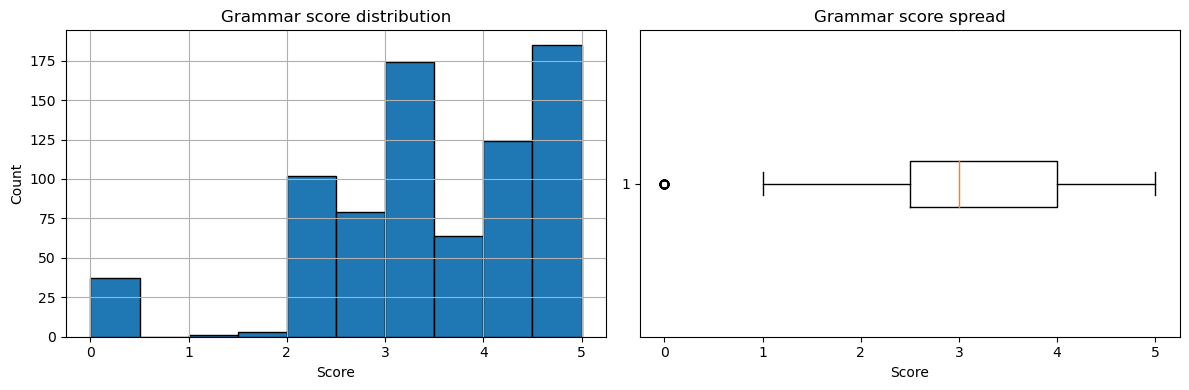

Test rows: 216 | sample_submission rows: 204
Filename overlap: 25
Test filenames absent from template: 191
Template filenames absent from test: 179


C:\Users\jagad\AppData\Local\Temp\ipykernel_25400\1866496419.py:32: UserWarning: The sample template and test.csv do not match. This notebook will create predictions for test.csv; confirm the expected submission file with the competition owner before uploading.
  warnings.warn(


In [3]:
required_cols = {"filename", "label"}
assert required_cols.issubset(train.columns), f"train.csv must contain columns: {required_cols}"
assert "filename" in test.columns, "test.csv must contain a filename column"
assert "filename" in sample_submission.columns, "sample_submission.csv must contain a filename column"
assert train["filename"].notna().all(), "Missing training filenames"
assert train["label"].notna().all(), "Missing training labels"
assert train["filename"].is_unique, "Duplicate training filenames detected"
assert test["filename"].notna().all(), "Missing test filenames"
assert test["filename"].is_unique, "Duplicate test filenames detected"
assert pd.to_numeric(train["label"], errors="coerce").notna().all(), "Training labels must be numeric"

print("Training label summary:")
display(train["label"].describe())
print("Unique labels:", sorted(train["label"].unique()))
print("Missing labels:", train["label"].isna().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train["label"].hist(ax=axes[0], bins=10, edgecolor="black")
axes[0].set(title="Grammar score distribution", xlabel="Score", ylabel="Count")
axes[1].boxplot(train["label"].dropna(), vert=False)
axes[1].set(title="Grammar score spread", xlabel="Score")
plt.tight_layout()
plt.show()

test_names = set(test["filename"].astype(str).str.strip())
sub_names = set(sample_submission["filename"].astype(str).str.strip())
print(f"Test rows: {len(test)} | sample_submission rows: {len(sample_submission)}")
print("Filename overlap:", len(test_names & sub_names))
print("Test filenames absent from template:", len(test_names - sub_names))
print("Template filenames absent from test:", len(sub_names - test_names))
if len(test) != len(sample_submission) or test_names != sub_names:
    warnings.warn(
        "The sample template and test.csv do not match. This notebook will create predictions for test.csv; "
        "confirm the expected submission file with the competition owner before uploading."
    )

## 5. Locate and validate audio files

The code searches recursively inside the extracted `train` and `test` folders. Make sure the folders exist and that their WAV filenames match the CSV filenames. If your WAVs are nested in subfolders, recursive search will still find them.

In [4]:
# Search recursively under the extracted training and test roots.
if not TRAIN_AUDIO_DIR.exists():
    raise FileNotFoundError(
        f"Training audio directory not found: {TRAIN_AUDIO_DIR}. "
        "Extract train.zip into Dataset_Final/train or update TRAIN_AUDIO_DIR."
    )
if not TEST_AUDIO_DIR.exists():
    raise FileNotFoundError(
        f"Test audio directory not found: {TEST_AUDIO_DIR}. "
        "Extract test.zip into Dataset_Final/test or update TEST_AUDIO_DIR."
    )

audio_paths = {}
duplicate_basenames = []
for root in [TRAIN_AUDIO_DIR, TEST_AUDIO_DIR]:
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() == ".wav":
            if path.name in audio_paths and audio_paths[path.name] != path:
                duplicate_basenames.append(path.name)
            else:
                audio_paths[path.name] = path

print("Unique WAV filenames found:", len(audio_paths))
if duplicate_basenames:
    print("Warning: duplicate WAV basenames found; verify filename uniqueness:", sorted(set(duplicate_basenames))[:10])

train_missing = [name for name in train["filename"].astype(str) if name not in audio_paths]
test_missing = [name for name in test["filename"].astype(str) if name not in audio_paths]
print("Training audio files missing:", len(train_missing))
print("Test audio files missing:", len(test_missing))
if train_missing[:10]:
    print("Examples of missing training files:", train_missing[:10])
if test_missing[:10]:
    print("Examples of missing test files:", test_missing[:10])

if train_missing or test_missing:
    warnings.warn("Some CSV filenames do not have matching WAV files. Fix the paths/filenames before modeling.")


Unique WAV filenames found: 773
Training audio files missing: 0
Test audio files missing: 0


## 6. Extract fixed-length audio features
We extract compact statistical features from the waveform: duration, MFCC means and standard deviations, spectral centroid, spectral bandwidth, spectral rolloff, zero-crossing rate, RMS energy, and a rough tempo estimate.

These features describe the audio signal and aspects of vocal delivery. **They do not explicitly understand grammar**, so treat this as a baseline, not the final scientific solution. If extraction fails for an individual file, the row is filled with missing values and handled by the model pipeline.

In [5]:
def extract_audio_features(path, sr=16000):
    """Extract robust, fixed-length acoustic features from one WAV file."""
    y, sr = librosa.load(path, sr=sr, mono=True)
    if y.size == 0:
        raise ValueError("Empty audio file")

    # Trim only leading/trailing silence for feature computation; duration uses original waveform.
    original_duration = len(y) / sr
    y_trim, _ = librosa.effects.trim(y, top_db=30)
    if y_trim.size == 0:
        y_trim = y

    features = {"duration_seconds": float(original_duration)}
    features["signal_rms"] = float(np.sqrt(np.mean(y_trim ** 2) + 1e-12))
    features["zero_crossing_mean"] = float(np.mean(librosa.feature.zero_crossing_rate(y=y_trim)))
    features["zero_crossing_std"] = float(np.std(librosa.feature.zero_crossing_rate(y=y_trim)))

    for feature_name, matrix in [
        ("mfcc", librosa.feature.mfcc(y=y_trim, sr=sr, n_mfcc=20)),
        ("spectral_centroid", librosa.feature.spectral_centroid(y=y_trim, sr=sr)),
        ("spectral_bandwidth", librosa.feature.spectral_bandwidth(y=y_trim, sr=sr)),
        ("spectral_rolloff", librosa.feature.spectral_rolloff(y=y_trim, sr=sr)),
        ("rms", librosa.feature.rms(y=y_trim)),
    ]:
        for i, row in enumerate(matrix):
            features[f"{feature_name}_{i+1}_mean"] = float(np.mean(row))
            features[f"{feature_name}_{i+1}_std"] = float(np.std(row))

    try:
        tempo = librosa.feature.tempo(y=y_trim, sr=sr)
        features["tempo_estimate"] = float(np.mean(tempo))
    except Exception:
        features["tempo_estimate"] = np.nan

    return features

def build_feature_table(filenames, audio_path_map):
    rows = []
    for i, filename in enumerate(filenames):
        path = audio_path_map.get(str(filename))
        if path is None:
            rows.append({"filename": str(filename), "feature_error": "file_not_found"})
            continue
        try:
            row = extract_audio_features(path)
            row["filename"] = str(filename)
            row["feature_error"] = ""
            rows.append(row)
        except Exception as exc:
            rows.append({"filename": str(filename), "feature_error": repr(exc)})
        if (i + 1) % 50 == 0:
            print(f"Processed {i+1}/{len(filenames)} audio files")
    return pd.DataFrame(rows)

train_features = build_feature_table(train["filename"], audio_paths)
test_features = build_feature_table(test["filename"], audio_paths)

print("Train feature table:", train_features.shape)
print("Test feature table:", test_features.shape)
print("Train feature extraction errors:", (train_features["feature_error"] != "").sum())
print("Test feature extraction errors:", (test_features["feature_error"] != "").sum())
display(train_features.head())

C:\Users\jagad\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


Processed 50/769 audio files
Processed 100/769 audio files
Processed 150/769 audio files
Processed 200/769 audio files
Processed 250/769 audio files
Processed 300/769 audio files
Processed 350/769 audio files
Processed 400/769 audio files
Processed 450/769 audio files
Processed 500/769 audio files
Processed 550/769 audio files
Processed 600/769 audio files
Processed 650/769 audio files
Processed 700/769 audio files
Processed 750/769 audio files
Processed 50/216 audio files
Processed 100/216 audio files
Processed 150/216 audio files
Processed 200/216 audio files
Train feature table: (769, 55)
Test feature table: (216, 55)
Train feature extraction errors: 0
Test feature extraction errors: 0


,duration_seconds,signal_rms,zero_crossing_mean,zero_crossing_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,spectral_centroid_1_std,spectral_bandwidth_1_mean,spectral_bandwidth_1_std,spectral_rolloff_1_mean,spectral_rolloff_1_std,rms_1_mean,rms_1_std,tempo_estimate,filename,feature_error
0,60.508375,0.051733,0.085115,0.055339,-392.413055,118.523796,110.194633,65.943123,-16.060364,37.793980,...,410.128581,889.024899,248.173318,1745.300050,675.488382,0.034187,0.038807,104.166667,audio_192.wav,
1,60.074688,0.089254,0.140762,0.128046,-286.123047,82.309677,72.856735,56.419323,5.143228,46.655106,...,1160.850107,1486.992064,490.319049,3230.634702,1854.939198,0.070095,0.055215,144.230769,audio_436.wav,
2,60.074688,0.075493,0.147271,0.130644,-323.148224,85.951721,98.142616,59.352917,19.015785,30.708570,...,1216.104482,1500.638894,538.756393,2941.621389,2092.659726,0.055158,0.051514,110.294118,audio_447.wav,
3,45.060000,0.018400,0.059477,0.036870,-489.320648,124.842316,111.792915,53.296013,0.751575,41.733734,...,471.566967,1177.252185,392.434373,1865.640525,1171.358114,0.013778,0.012183,110.294118,audio_126.wav,
4,45.300000,0.013402,0.173728,0.130175,-466.660675,151.008316,55.453632,59.216469,-23.247295,45.416168,...,1046.379738,1578.423216,409.261206,3868.766559,1524.704346,0.009997,0.008923,104.166667,audio_61.wav,


## 7. Optional speech transcription and linguistic features

Grammar is primarily expressed in the words and sentence structure, while acoustic features mostly describe vocal delivery. When enabled, this section uses `faster-whisper` to transcribe the audio and extracts simple text-structure features (word/sentence counts, sentence-length statistics, lexical diversity, fillers, repeated adjacent words, and selected function-word counts).

These are **proxy features, not a direct grammar checker**. ASR errors can introduce noise, so compare their cross-validation RMSE against the acoustic-only baseline. Set `USE_TRANSCRIPT_FEATURES = False` in the configuration cell to skip this computationally expensive step.

In [6]:
import re
from collections import Counter

def extract_text_features(text):
    """Create fixed-length, lightweight linguistic features from an ASR transcript."""
    text = "" if text is None else str(text).strip()
    words = re.findall(r"\b[\w']+\b", text.lower())
    sentences = [s.strip() for s in re.split(r"[.!?]+", text) if s.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    counts = Counter(words)
    n_words = len(words)
    n_sentences = len(sentences)
    unique_words = len(set(words))
    repeated_adjacent = sum(1 for a, b in zip(words, words[1:]) if a == b)
    fillers = {"um", "uh", "erm", "ah", "hmm", "mm"}
    function_words = {
        "articles": {"a", "an", "the"},
        "pronouns": {"i", "me", "my", "we", "us", "our", "you", "he", "him", "she", "her", "it", "they", "them", "their"},
        "auxiliaries": {"am", "is", "are", "was", "were", "be", "been", "being", "do", "does", "did", "have", "has", "had", "will", "would", "can", "could", "should", "may", "might", "must"},
        "conjunctions": {"and", "but", "or", "because", "although", "while", "if", "when", "so"},
        "prepositions": {"in", "on", "at", "by", "for", "from", "with", "about", "into", "over", "under", "between", "of", "to"},
    }
    features = {
        "transcript_word_count": float(n_words),
        "transcript_sentence_count": float(n_sentences),
        "transcript_unique_word_ratio": float(unique_words / max(n_words, 1)),
        "transcript_avg_sentence_length": float(np.mean(sentence_lengths)) if sentence_lengths else 0.0,
        "transcript_sentence_length_std": float(np.std(sentence_lengths)) if sentence_lengths else 0.0,
        "transcript_max_sentence_length": float(max(sentence_lengths)) if sentence_lengths else 0.0,
        "transcript_filler_rate": float(sum(counts[w] for w in fillers) / max(n_words, 1)),
        "transcript_adjacent_repeat_rate": float(repeated_adjacent / max(n_words - 1, 1)),
        "transcript_question_mark_count": float(text.count("?")),
        "transcript_comma_count": float(text.count(",")),
        "transcript_avg_word_length": float(np.mean([len(w) for w in words])) if words else 0.0,
    }
    for name, vocab in function_words.items():
        features[f"transcript_{name}_rate"] = float(sum(counts[w] for w in vocab) / max(n_words, 1))
    return features

def transcribe_audio_files(filenames, audio_path_map):
    """Transcribe audio files with faster-whisper and return one feature row per filename."""
    try:
        from faster_whisper import WhisperModel
    except ImportError as exc:
        raise ImportError(
            "faster-whisper is required. Run the dependency-installation cell, "
            "or set USE_TRANSCRIPT_FEATURES = False."
        ) from exc

    print(f"Loading Whisper model: {WHISPER_MODEL_SIZE} ({WHISPER_DEVICE}/{WHISPER_COMPUTE_TYPE})")
    model = WhisperModel(
        WHISPER_MODEL_SIZE,
        device=WHISPER_DEVICE,
        compute_type=WHISPER_COMPUTE_TYPE,
    )
    rows = []
    cache = {}
    for i, filename in enumerate(filenames):
        name = str(filename)
        path = audio_path_map.get(name)
        if path is None:
            transcript = ""
            status = "file_not_found"
        elif name in cache:
            transcript = cache[name]
            status = ""
        else:
            try:
                segments, info = model.transcribe(
                    str(path), language="en", beam_size=1, vad_filter=True
                )
                transcript = " ".join(segment.text.strip() for segment in segments).strip()
                cache[name] = transcript
                status = ""
            except Exception as exc:
                transcript = ""
                status = f"transcription_error: {type(exc).__name__}"
        row = {"filename": name, "transcript": transcript, "transcription_error": status}
        row.update(extract_text_features(transcript))
        rows.append(row)
        if (i + 1) % 25 == 0 or i + 1 == len(filenames):
            print(f"Transcribed {i+1}/{len(filenames)} files")
    return pd.DataFrame(rows)

if USE_TRANSCRIPT_FEATURES:
    train_text_features = transcribe_audio_files(train["filename"], audio_paths)
    test_text_features = transcribe_audio_files(test["filename"], audio_paths)

    # Keep transcripts for audit/debugging, but only numeric features enter the model.
    train_text_features.to_csv(DATASET_DIR / "train_transcript_features.csv", index=False)
    test_text_features.to_csv(DATASET_DIR / "test_transcript_features.csv", index=False)

    text_numeric_cols = [
        c for c in train_text_features.columns
        if c.startswith("transcript_") and pd.api.types.is_numeric_dtype(train_text_features[c])
    ]
    train_features = train_features.merge(
        train_text_features[["filename"] + text_numeric_cols], on="filename", how="left", validate="one_to_one"
    )
    test_features = test_features.merge(
        test_text_features[["filename"] + text_numeric_cols], on="filename", how="left", validate="one_to_one"
    )
    print("Added transcript-derived features:", len(text_numeric_cols))
    print("Transcription errors (train/test):",
          (train_text_features["transcription_error"] != "").sum(),
          (test_text_features["transcription_error"] != "").sum())
else:
    print("Transcript features disabled; continuing with acoustic features only.")

Transcript features disabled; continuing with acoustic features only.


## 8. Prepare model matrices and handle missing features
We keep only numeric features and align test columns to training columns. A median imputer handles occasional extraction failures. Scaling is used for Ridge and SVR; tree models generally do not require scaling.

In [7]:
drop_cols = {"filename", "feature_error"}
feature_cols = [c for c in train_features.columns if c not in drop_cols and pd.api.types.is_numeric_dtype(train_features[c])]
X = train_features[feature_cols].replace([np.inf, -np.inf], np.nan)
X_test = test_features.reindex(columns=train_features.columns).reindex(columns=feature_cols)
X_test = X_test.replace([np.inf, -np.inf], np.nan)
y = train["label"].astype(float)

if X.shape[1] == 0:
    raise ValueError("No numeric audio features were extracted. Check AUDIO_DIR and WAV files.")

print("Feature count:", len(feature_cols))
print("Rows with all features missing:", X.isna().all(axis=1).sum())
print("Rows with all test features missing:", X_test.isna().all(axis=1).sum())

Feature count: 53
Rows with all features missing: 0
Rows with all test features missing: 0


## 9. Compare regression models with cross-validation
We use shuffled 5-fold cross-validation and RMSE. Each fold holds out a portion of the training data, giving a more realistic estimate than training error alone.

Because this is a small dataset, results may vary by fold. Do not select a model based only on its training RMSE.

In [8]:
# Compare baseline models, then tune the strongest low-cost candidates.
# Keep n_jobs=1 to reduce memory pressure and avoid Windows multiprocessing issues.
from sklearn.model_selection import GridSearchCV

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

models = {
    "Dummy mean baseline": make_pipeline(DummyRegressor(strategy="mean")),
    "Ridge baseline": make_pipeline(Ridge(alpha=10.0), scale=True),
    "SVR RBF baseline": make_pipeline(SVR(C=3.0, epsilon=0.2, kernel="rbf"), scale=True),
    "Random Forest": make_pipeline(RandomForestRegressor(
        n_estimators=250, min_samples_leaf=3, max_features=0.8,
        random_state=RANDOM_STATE, n_jobs=1)),
    "Extra Trees": make_pipeline(ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=2, max_features=0.8,
        random_state=RANDOM_STATE, n_jobs=1)),
    "Hist Gradient Boosting": make_pipeline(HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
        l2_regularization=2.0, random_state=RANDOM_STATE))
}

results = []
for name, pipe in models.items():
    neg_mse = cross_val_score(pipe, X, y, cv=cv, scoring="neg_mean_squared_error", n_jobs=1)
    rmse_folds = np.sqrt(-neg_mse)
    results.append({"model": name, "cv_rmse_mean": rmse_folds.mean(),
                    "cv_rmse_std": rmse_folds.std(), "fold_rmse": rmse_folds})
    print(f"{name:24s} CV RMSE = {rmse_folds.mean():.4f} ± {rmse_folds.std():.4f}")

# Hyperparameter tuning: moderate grid to improve CV RMSE without using Whisper.
svr_pipeline = make_pipeline(SVR(kernel="rbf"), scale=True)
svr_grid = {
    "model__C": [0.5, 1, 3, 10, 20],
    "model__epsilon": [0.05, 0.1, 0.2, 0.3],
    "model__gamma": ["scale", 0.01, 0.05, 0.1],
}
svr_search = GridSearchCV(
    svr_pipeline, param_grid=svr_grid, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=1, refit=True,
    return_train_score=True, verbose=1
)
svr_search.fit(X, y)
svr_cv_rmse = -float(svr_search.best_score_)
print("\nTuned SVR best CV RMSE:", round(svr_cv_rmse, 4))
print("Tuned SVR parameters:", svr_search.best_params_)

ridge_pipeline = make_pipeline(Ridge(), scale=True)
ridge_grid = {"model__alpha": [0.1, 1, 3, 10, 30, 100, 300]}
ridge_search = GridSearchCV(
    ridge_pipeline, param_grid=ridge_grid, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=1, refit=True,
    return_train_score=True
)
ridge_search.fit(X, y)
ridge_cv_rmse = -float(ridge_search.best_score_)
print("Tuned Ridge best CV RMSE:", round(ridge_cv_rmse, 4))
print("Tuned Ridge parameters:", ridge_search.best_params_)

# Add tuned models to the comparison table. Grid-search CV scores are selected from
# the same folds, so treat them as tuning estimates rather than a fully unbiased final estimate.
results.append({"model": "Tuned SVR RBF", "cv_rmse_mean": svr_cv_rmse,
                "cv_rmse_std": float(svr_search.cv_results_["std_test_score"][svr_search.best_index_]),
                "fold_rmse": None})
results.append({"model": "Tuned Ridge", "cv_rmse_mean": ridge_cv_rmse,
                "cv_rmse_std": float(ridge_search.cv_results_["std_test_score"][ridge_search.best_index_]),
                "fold_rmse": None})
results_df = pd.DataFrame([{k: v for k, v in r.items() if k != "fold_rmse"} for r in results])
results_df = results_df.sort_values("cv_rmse_mean").reset_index(drop=True)
display(results_df)

# Choose the best CV candidate, retaining the fitted GridSearchCV estimator for tuned models.
candidate_models = dict(models)
candidate_models["Tuned SVR RBF"] = svr_search.best_estimator_
candidate_models["Tuned Ridge"] = ridge_search.best_estimator_
best_name = results_df.iloc[0]["model"]
best_model = candidate_models[best_name]
print("Selected model by CV RMSE:", best_name)
print("Selected CV RMSE: {:.4f} ± {:.4f}".format(
    results_df.iloc[0]["cv_rmse_mean"], results_df.iloc[0]["cv_rmse_std"]))


Dummy mean baseline      CV RMSE = 1.2397 ± 0.0634
Ridge baseline           CV RMSE = 0.8499 ± 0.0639
SVR RBF baseline         CV RMSE = 0.7271 ± 0.0362
Random Forest            CV RMSE = 0.7866 ± 0.0415
Extra Trees              CV RMSE = 0.7523 ± 0.0447


C:\Users\jagad\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\jagad\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\jagad\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\jagad\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\jagad\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Hist Gradient Boosting   CV RMSE = 0.7939 ± 0.0337
Fitting 5 folds for each of 80 candidates, totalling 400 fits

Tuned SVR best CV RMSE: 0.7033
Tuned SVR parameters: {'model__C': 10, 'model__epsilon': 0.05, 'model__gamma': 0.05}
Tuned Ridge best CV RMSE: 0.8453
Tuned Ridge parameters: {'model__alpha': 100}


,model,cv_rmse_mean,cv_rmse_std
0,Tuned SVR RBF,0.703314,0.027502
1,SVR RBF baseline,0.727108,0.036156
2,Extra Trees,0.752280,0.044747
3,Random Forest,0.786641,0.041523
4,Hist Gradient Boosting,0.793896,0.033699
5,Tuned Ridge,0.845272,0.058719
6,Ridge baseline,0.849865,0.063887
7,Dummy mean baseline,1.239723,0.063385


Selected model by CV RMSE: Tuned SVR RBF
Selected CV RMSE: 0.7033 ± 0.0275


## 10. Fit selected model and report the required training RMSE
The competition explicitly requires the **training-data RMSE** in the final notebook. This is calculated on the same labelled examples used to fit the final model, so it is an in-sample metric and will usually look better than cross-validation RMSE. Report both values and do not present training RMSE as a generalization estimate.

REQUIRED TRAINING RMSE: 0.0481
Training MAE: 0.0472
Training R²: 0.9985
Selected model CV RMSE: 0.7033 ± 0.0275


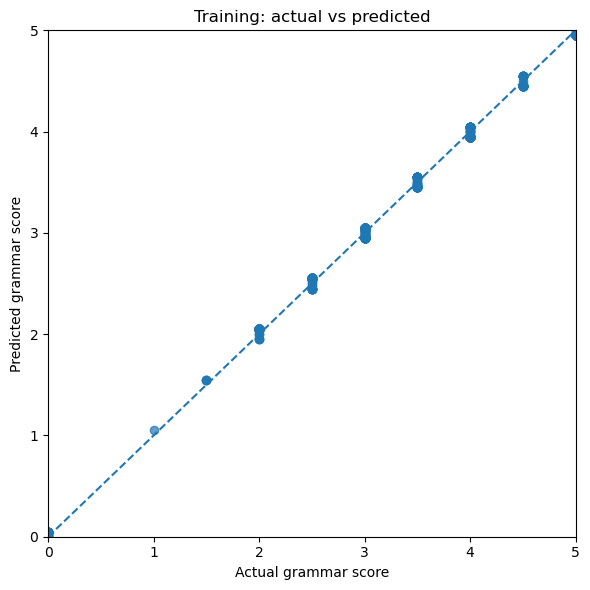

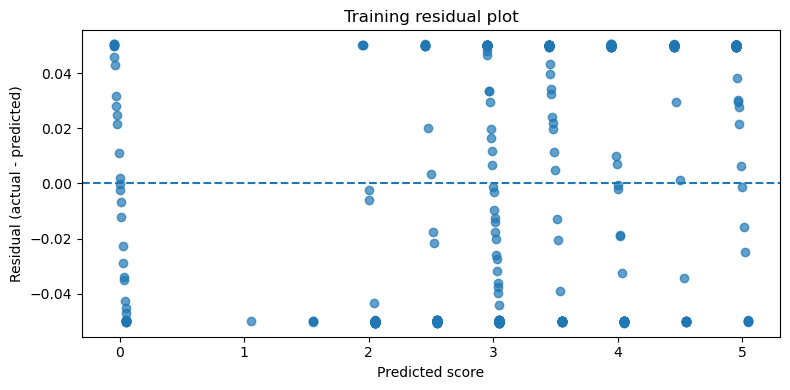

In [9]:
best_model.fit(X, y)
train_predictions = best_model.predict(X)
train_rmse = float(np.sqrt(mean_squared_error(y, train_predictions)))
train_mae = float(mean_absolute_error(y, train_predictions))
train_r2 = float(r2_score(y, train_predictions))

print(f"REQUIRED TRAINING RMSE: {train_rmse:.4f}")
print(f"Training MAE: {train_mae:.4f}")
print(f"Training R²: {train_r2:.4f}")
print(f"Selected model CV RMSE: {results_df.iloc[0]['cv_rmse_mean']:.4f} ± {results_df.iloc[0]['cv_rmse_std']:.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(y, train_predictions, alpha=0.7)
plt.plot([0, 5], [0, 5], linestyle="--")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("Actual grammar score")
plt.ylabel("Predicted grammar score")
plt.title("Training: actual vs predicted")
plt.tight_layout()
plt.show()

residuals = y - train_predictions
plt.figure(figsize=(8, 4))
plt.scatter(train_predictions, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted score")
plt.ylabel("Residual (actual - predicted)")
plt.title("Training residual plot")
plt.tight_layout()
plt.show()

## 11. Generate evaluation predictions and validate the submission

The code predicts every filename listed in `test.csv` (216 rows according to the competition description) and writes a separate candidate file named `submission_corrected.csv`. It does not overwrite the earlier `submission.csv` or its backup. The provided sample template has a different row count and filename list, so the notebook reports this mismatch and warns you to verify the platform's required format before uploading.

In [10]:
# Predict every row in test.csv and save a candidate file.
test_predictions = np.clip(best_model.predict(X_test), 0.0, 5.0)

predictions_by_filename = pd.DataFrame({
    "filename": test["filename"].astype(str).str.strip(),
    "label": test_predictions.astype(float),
})

# Basic prediction validation.
assert len(predictions_by_filename) == len(test), "Prediction count must match test.csv"
assert predictions_by_filename["filename"].equals(test["filename"].astype(str).str.strip()), "Test filename order changed"
assert predictions_by_filename["filename"].is_unique, "Duplicate filenames in predictions"
assert predictions_by_filename["label"].notna().all(), "Missing predictions"
assert np.isfinite(predictions_by_filename["label"]).all(), "Non-finite predictions found"
assert predictions_by_filename["label"].between(0.0, 5.0).all(), "Predictions outside 0–5 range"

# Save a candidate for the complete test.csv. Do not assume it is upload-ready.
candidate_path = DATASET_DIR / "submission_corrected.csv"
predictions_by_filename.to_csv(candidate_path, index=False)
print("Saved test.csv prediction candidate:", candidate_path)
print("Candidate rows:", len(predictions_by_filename))
print("Candidate columns:", predictions_by_filename.columns.tolist())

test_names = test["filename"].astype(str).str.strip().tolist()
template_names = sample_submission["filename"].astype(str).str.strip().tolist()
test_name_set, template_name_set = set(test_names), set(template_names)
exact_same_filenames = (len(test_names) == len(template_names) and test_name_set == template_name_set)
print("\n--- Submission template validation ---")
print("test.csv rows:", len(test_names))
print("sample_submission.csv rows:", len(template_names))
print("Filename overlap:", len(test_name_set & template_name_set))
print("Test filenames absent from template:", len(test_name_set - template_name_set))
print("Template filenames absent from test:", len(template_name_set - test_name_set))
print("Exact filename match:", exact_same_filenames)

# Write a diagnostics file to help resolve the mismatch with the competition owner.
diagnostics = pd.DataFrame({
    "test_filename_not_in_template": pd.Series(sorted(test_name_set - template_name_set), dtype="string"),
    "template_filename_not_in_test": pd.Series(sorted(template_name_set - test_name_set), dtype="string"),
})
diagnostics_path = DATASET_DIR / "submission_template_diagnostics.csv"
diagnostics.to_csv(diagnostics_path, index=False)
print("Saved filename mismatch diagnostics:", diagnostics_path)

if exact_same_filenames:
    # Align predictions to the exact order requested by the template.
    pred_map = predictions_by_filename.set_index("filename")["label"]
    aligned_submission = pd.DataFrame({
        "filename": template_names,
        "label": [float(pred_map[name]) for name in template_names],
    })
    aligned_path = DATASET_DIR / "submission_template_aligned.csv"
    aligned_submission.to_csv(aligned_path, index=False)
    print("Template-aligned submission saved:", aligned_path)
else:
    print("\nSTOP: Do NOT upload submission_corrected.csv yet.")
    print("The provided template and test.csv disagree substantially. Confirm the official test/template files or expected submission format with the competition organizer.")

display(predictions_by_filename.head())


Saved test.csv prediction candidate: C:\Users\jagad\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission_corrected.csv
Candidate rows: 216
Candidate columns: ['filename', 'label']

--- Submission template validation ---
test.csv rows: 216
sample_submission.csv rows: 204
Filename overlap: 25
Test filenames absent from template: 191
Template filenames absent from test: 179
Exact filename match: False
Saved filename mismatch diagnostics: C:\Users\jagad\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission_template_diagnostics.csv

STOP: Do NOT upload submission_corrected.csv yet.
The provided template and test.csv disagree substantially. Confirm the official test/template files or expected submission format with the competition organizer.


,filename,label
0,audio_128.wav,2.050062
1,audio_156.wav,3.449735
2,audio_19.wav,3.049788
3,audio_108.wav,1.049701
4,audio_206.wav,4.949890


## 12. Feature importance (interpretability)

Feature importance is calculated using a separate Extra Trees model so this section works even when the best cross-validation model is SVR or Ridge. These importances show which acoustic features the tree model used most; they do **not** prove that those features directly measure grammar.

Top 10 features (separate Extra Trees model):


,Feature,Importance
2,zero_crossing_mean,0.082749
7,mfcc_2_std,0.072133
9,mfcc_3_std,0.070396
4,mfcc_1_mean,0.065474
48,spectral_rolloff_1_mean,0.040211
44,spectral_centroid_1_mean,0.039928
11,mfcc_4_std,0.036009
5,mfcc_1_std,0.035895
19,mfcc_8_std,0.033051
49,spectral_rolloff_1_std,0.028762


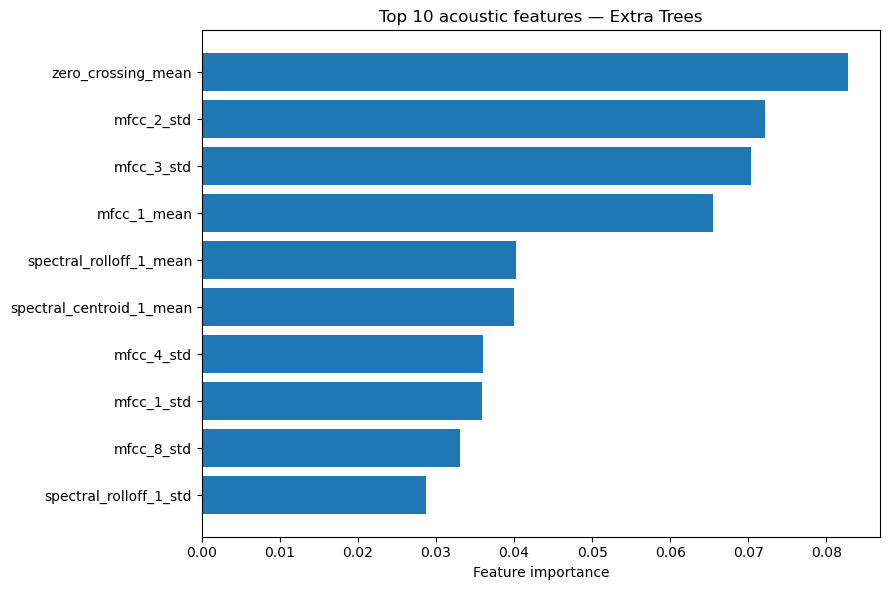

In [11]:
# Fit a separate tree model for feature-importance analysis.
importance_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2
    )),
])
importance_model.fit(X, y)

importance_values = importance_model.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"Feature": X.columns, "Importance": importance_values})
importance_df = importance_df.sort_values("Importance", ascending=False)
print("Top 10 features (separate Extra Trees model):")
display(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")
plt.title("Top 10 acoustic features — Extra Trees")
plt.tight_layout()
plt.show()

## 13. Brief report and final checklist

### Approach
The notebook extracts fixed-length acoustic summary features using Librosa. When enabled, it also transcribes the recordings with faster-whisper and adds lightweight text-structure features. These transcript features are imperfect proxies and can be affected by speech-recognition errors.

### Preprocessing and pipeline
WAV files → audio validation → Librosa acoustic features → optional English transcription → text-structure features → numeric feature matrix → median imputation (and scaling for models that need it) → regression model comparison → best model selected by 5-fold CV RMSE → final fit → bounded test predictions → CSV validation.

### Evaluation
The notebook prints the **required training-data RMSE**, training MAE/R², and five-fold CV RMSE. Training RMSE is in-sample and usually optimistic; use CV RMSE to compare models. Actual scores are computed at runtime and must not be hard-coded.

### Limitations
There are only 769 labelled recordings. Acoustic properties do not directly measure syntax, and ASR may misrecognize words. The text features in this notebook are simple structural indicators, not a full grammar checker. Compare acoustic-only and acoustic-plus-text CV RMSE before deciding which version to submit.

### Submission warning
The notebook creates a candidate submission with one row per `test.csv` row. It checks whether the provided sample template has the same filenames and row count. If the template still differs from `test.csv`, do not upload blindly: confirm the expected evaluation IDs and column names in the competition portal.

### Final checklist
- Confirm `PROJECT_DIR` points to the folder containing `Dataset_Final`.
- Run **Kernel → Restart Kernel and Run All Cells**.
- Allow time for Whisper's first model download and transcription; use `WHISPER_MODEL_SIZE = "tiny"` for a faster first test.
- Confirm the required training RMSE and CV RMSE appear in the output.
- Inspect extraction/transcription error counts and the CV comparison table.
- Validate the submission schema against the competition's actual expected format.